In [ ]:
from google.colab import files
uploaded = files.upload()

Saving archive.zip to archive.zip


In [ ]:
import zipfile, os

with zipfile.ZipFile("/content/archive.zip", 'r') as zip_ref:
    zip_ref.extractall("/content/soybean_dataset")

def find_dataset_root(base_path):
    for root, dirs, files_ in os.walk(base_path):
        if dirs and all(
            any(f.lower().endswith(('.jpg', '.jpeg', '.png'))
                for f in os.listdir(os.path.join(root, d)))
            for d in dirs if os.path.isdir(os.path.join(root, d))
        ):
            return root
    return base_path

dataset_path = find_dataset_root("/content/soybean_dataset")
print("dataset_path:", dataset_path)
print("Classes:", os.listdir(dataset_path))

dataset_path: /content/soybean_dataset/Soybean Seeds
Classes: ['Skin-damaged soybeans', 'Spotted soybeans', 'Intact soybeans', 'Immature soybeans', 'Broken soybeans']


In [ ]:
import torch, random, time
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [ ]:
!pip install imagehash scikit-image -q
import imagehash
from PIL import Image
from collections import defaultdict
import itertools

def compute_hashes(dataset_path):
    hash_map = defaultdict(list)
    all_files = []
    for class_name in os.listdir(dataset_path):
        class_dir = os.path.join(dataset_path, class_name)
        if not os.path.isdir(class_dir):
            continue
        for fname in os.listdir(class_dir):
            fpath = os.path.join(class_dir, fname)
            try:
                img = Image.open(fpath).convert("RGB")
                h = imagehash.phash(img)
                hash_map[h].append(fpath)
                all_files.append(fpath)
            except Exception as e:
                print("Skipping", fpath, e)
    return hash_map, all_files

hash_map, all_files = compute_hashes(dataset_path)
print(f"Total images: {len(all_files)}, unique hashes: {len(hash_map)}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 20.8 MB/s eta 0:00:00
Total images: 5513, unique hashes: 5195


In [ ]:
def cluster_by_similarity(hash_map, max_distance=8):
    hashes = list(hash_map.keys())
    parent = {h: h for h in hashes}
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    def union(x, y):
        parent[find(x)] = find(y)
    for h1, h2 in itertools.combinations(hashes, 2):
        if h1 - h2 <= max_distance:
            union(h1, h2)
    cluster_map = {}
    for h in hashes:
        root = find(h)
        for fpath in hash_map[h]:
            cluster_map[fpath] = str(root)
    return cluster_map

cluster_map = cluster_by_similarity(hash_map, max_distance=8)

base_dataset = datasets.ImageFolder(root=dataset_path)
samples = base_dataset.samples
filepaths = [s[0] for s in samples]
labels = [s[1] for s in samples]
groups = [cluster_map[fp] for fp in filepaths]
num_classes = len(base_dataset.classes)
class_names = base_dataset.classes
print("Classes:", class_names)

gss = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=SEED)
train_idx, test_idx = next(gss.split(filepaths, labels, groups=groups))

print(f"Train: {len(train_idx)}, Test: {len(test_idx)}")
train_groups = set(groups[i] for i in train_idx)
test_groups = set(groups[i] for i in test_idx)
print("Overlap (should be 0):", len(train_groups & test_groups))

train_labels = [labels[i] for i in train_idx]
class_weights = compute_class_weight('balanced', classes=np.unique(train_labels), y=train_labels)
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)

Classes: ['Broken soybeans', 'Immature soybeans', 'Intact soybeans', 'Skin-damaged soybeans', 'Spotted soybeans']
Train: 4776, Test: 737
Overlap (should be 0): 0


In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomCrop(224, padding=8),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder(root=dataset_path, transform=train_transform)
test_dataset  = datasets.ImageFolder(root=dataset_path, transform=test_transform)

train_loader = DataLoader(Subset(train_dataset, train_idx), batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
test_loader  = DataLoader(Subset(test_dataset, test_idx), batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

print("Classes:", train_dataset.classes)

Classes: ['Broken soybeans', 'Immature soybeans', 'Intact soybeans', 'Skin-damaged soybeans', 'Spotted soybeans']


In [ ]:
def mixup_data(x, y, alpha=0.15):
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1
    index = torch.randperm(x.size(0)).to(x.device)
    return lam * x + (1 - lam) * x[index, :], y, y[index], lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

from torch.optim.lr_scheduler import LinearLR, CosineAnnealingLR, SequentialLR

def build_scheduler(optimizer, epochs, warmup_epochs=3):
    warmup = LinearLR(optimizer, start_factor=0.1, total_iters=warmup_epochs)
    cosine = CosineAnnealingLR(optimizer, T_max=epochs - warmup_epochs, eta_min=1e-6)
    return SequentialLR(optimizer, schedulers=[warmup, cosine], milestones=[warmup_epochs])

def train_model(model, train_loader, test_loader, criterion, optimizer, scheduler,
                 epochs, save_name, patience=15, mixup_alpha=0.15):
    best_acc, epochs_no_improve = 0.0, 0

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0

        train_start = time.time()
        for images, lbls in train_loader:
            images, lbls = images.to(device), lbls.to(device)
            optimizer.zero_grad()
            images_m, labels_a, labels_b, lam = mixup_data(images, lbls, alpha=mixup_alpha)
            outputs = model(images_m)
            loss = mixup_criterion(criterion, outputs, labels_a, labels_b, lam)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, preds = torch.max(outputs, 1)
            correct += (lam * (preds == labels_a).sum().item() + (1 - lam) * (preds == labels_b).sum().item())
            total += lbls.size(0)
        train_time = time.time() - train_start

        scheduler.step()
        train_acc = 100 * correct / total

        model.eval()
        val_correct, val_total = 0, 0
        val_start = time.time()
        with torch.no_grad():
            for images, lbls in test_loader:
                images, lbls = images.to(device), lbls.to(device)
                outputs = model(images)
                _, preds = torch.max(outputs, 1)
                val_correct += (preds == lbls).sum().item()
                val_total += lbls.size(0)
        val_time = time.time() - val_start
        val_acc = 100 * val_correct / val_total

        print("-" * 70)
        print(f"Epoch [{epoch+1}/{epochs}]")
        print(f"Train Loss      : {running_loss/len(train_loader):.4f}")
        print(f"Train Accuracy  : {train_acc:.2f}%")
        print(f"Train Time      : {train_time:.2f}s")
        print(f"Validation Acc  : {val_acc:.2f}%")
        print(f"Validation Time : {val_time:.2f}s")

        if val_acc > best_acc:
            best_acc, epochs_no_improve = val_acc, 0
            torch.save(model.state_dict(), save_name)
            print("Best Model Saved")
        else:
            epochs_no_improve += 1
            print(f"No improvement for {epochs_no_improve} epoch(s)")

        if epochs_no_improve >= patience:
            print(f"\nEarly stopping triggered at epoch {epoch+1}")
            break

    print("\nTraining Finished")
    print(f"Best Validation Accuracy : {best_acc:.2f}%")
    return best_acc

def evaluate_model(model, weight_path, test_loader, class_names, print_report=True):
    model.load_state_dict(torch.load(weight_path))
    model.eval()
    predictions, labels_list = [], []
    start = time.time()
    with torch.no_grad():
        for images, lbls in test_loader:
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            predictions.extend(preds.cpu().numpy())
            labels_list.extend(lbls.numpy())
    elapsed_ms = (time.time() - start) * 1000 / len(test_loader.dataset)
    acc = accuracy_score(labels_list, predictions)
    if print_report:
        print(classification_report(labels_list, predictions, target_names=class_names))
        print(confusion_matrix(labels_list, predictions))
        print(f"Accuracy: {acc*100:.2f}% | Inference: {elapsed_ms:.2f} ms/img")
    n_params = sum(p.numel() for p in model.parameters())
    return acc, confusion_matrix(labels_list, predictions), elapsed_ms, n_params

In [ ]:
vit_model = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)
for param in vit_model.parameters():
    param.requires_grad = False
for block in vit_model.encoder.layers[-6:]:
    for param in block.parameters():
        param.requires_grad = True
for param in vit_model.encoder.ln.parameters():
    param.requires_grad = True
vit_model.heads.head = nn.Sequential(
    nn.Dropout(0.5), nn.Linear(768, 256), nn.ReLU(),
    nn.Dropout(0.3), nn.Linear(256, num_classes)
)
vit_model = vit_model.to(device)

epochs = 50
criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
optimizer = optim.AdamW([
    {'params': [p for p in vit_model.encoder.layers[-6:].parameters() if p.requires_grad], 'lr': 1.5e-5},
    {'params': vit_model.encoder.ln.parameters(), 'lr': 1.5e-5},
    {'params': vit_model.heads.parameters(), 'lr': 6e-5}
], weight_decay=4e-2)
scheduler = build_scheduler(optimizer, epochs, warmup_epochs=3)

train_model(vit_model, train_loader, test_loader, criterion, optimizer, scheduler,
            epochs=epochs, save_name="best_vit.pth", patience=15, mixup_alpha=0.15)

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:04<00:00, 85.1MB/s]


----------------------------------------------------------------------
Epoch [1/50]
Train Loss      : 1.5618
Train Accuracy  : 30.97%
Train Time      : 124.65s
Validation Acc  : 71.10%
Validation Time : 9.77s
Best Model Saved
----------------------------------------------------------------------
Epoch [2/50]
Train Loss      : 1.0850
Train Accuracy  : 70.44%
Train Time      : 131.80s
Validation Acc  : 89.69%
Validation Time : 9.88s
Best Model Saved
----------------------------------------------------------------------
Epoch [3/50]
Train Loss      : 0.7738
Train Accuracy  : 84.08%
Train Time      : 132.54s
Validation Acc  : 91.86%
Validation Time : 9.89s
Best Model Saved
----------------------------------------------------------------------
Epoch [4/50]
Train Loss      : 0.7170
Train Accuracy  : 86.52%
Train Time      : 132.00s
Validation Acc  : 92.54%
Validation Time : 9.86s
Best Model Saved
----------------------------------------------------------------------
Epoch [5/50]
Train Loss  

95.5223880597015

In [ ]:
vit_acc, vit_cm, vit_time, vit_params = evaluate_model(vit_model, "best_vit.pth", test_loader, class_names)

                       precision    recall  f1-score   support

      Broken soybeans       0.95      0.92      0.94       175
    Immature soybeans       0.97      0.97      0.97       114
      Intact soybeans       0.95      0.96      0.96       113
Skin-damaged soybeans       0.97      0.96      0.97       165
     Spotted soybeans       0.94      0.96      0.95       170

             accuracy                           0.96       737
            macro avg       0.96      0.96      0.96       737
         weighted avg       0.96      0.96      0.96       737

[[161   1   0   4   9]
 [  0 111   3   0   0]
 [  0   3 109   1   0]
 [  3   0   2 159   1]
 [  5   0   1   0 164]]
Accuracy: 95.52% | Inference: 13.33 ms/img


In [ ]:
resnet_model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
for param in resnet_model.parameters():
    param.requires_grad = False
for param in resnet_model.layer4.parameters():
    param.requires_grad = True
resnet_model.fc = nn.Sequential(
    nn.Dropout(0.5), nn.Linear(2048, 256), nn.ReLU(),
    nn.Dropout(0.3), nn.Linear(256, num_classes)
)
resnet_model = resnet_model.to(device)

resnet_optimizer = optim.AdamW([
    {'params': resnet_model.layer4.parameters(), 'lr': 1e-5},
    {'params': resnet_model.fc.parameters(), 'lr': 1e-4}
], weight_decay=4e-2)
resnet_scheduler = build_scheduler(resnet_optimizer, 45, warmup_epochs=3)

train_model(resnet_model, train_loader, test_loader, criterion, resnet_optimizer, resnet_scheduler,
            epochs=45, save_name="best_resnet50.pth", patience=15, mixup_alpha=0.15)
resnet_acc, resnet_cm, resnet_time, resnet_params = evaluate_model(resnet_model, "best_resnet50.pth", test_loader, class_names)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 210MB/s]


----------------------------------------------------------------------
Epoch [1/45]
Train Loss      : 1.6018
Train Accuracy  : 24.97%
Train Time      : 28.34s
Validation Acc  : 35.82%
Validation Time : 2.80s
Best Model Saved
----------------------------------------------------------------------
Epoch [2/45]
Train Loss      : 1.5287
Train Accuracy  : 41.16%
Train Time      : 28.02s
Validation Acc  : 55.09%
Validation Time : 2.85s
Best Model Saved
----------------------------------------------------------------------
Epoch [3/45]
Train Loss      : 1.2869
Train Accuracy  : 59.05%
Train Time      : 28.78s
Validation Acc  : 73.41%
Validation Time : 2.86s
Best Model Saved
----------------------------------------------------------------------
Epoch [4/45]
Train Loss      : 1.0314
Train Accuracy  : 69.94%
Train Time      : 28.25s
Validation Acc  : 84.53%
Validation Time : 2.82s
Best Model Saved
----------------------------------------------------------------------
Epoch [5/45]
Train Loss      

In [ ]:
densenet_model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
for param in densenet_model.parameters():
    param.requires_grad = False
for param in densenet_model.features.denseblock4.parameters():
    param.requires_grad = True
densenet_model.classifier = nn.Sequential(
    nn.Dropout(0.5), nn.Linear(1024, 256), nn.ReLU(),
    nn.Dropout(0.3), nn.Linear(256, num_classes)
)
densenet_model = densenet_model.to(device)

densenet_optimizer = optim.AdamW([
    {'params': densenet_model.features.denseblock4.parameters(), 'lr': 1e-5},
    {'params': densenet_model.classifier.parameters(), 'lr': 1e-4}
], weight_decay=4e-2)
densenet_scheduler = build_scheduler(densenet_optimizer, 45, warmup_epochs=3)

train_model(densenet_model, train_loader, test_loader, criterion, densenet_optimizer, densenet_scheduler,
            epochs=45, save_name="best_densenet121.pth", patience=15, mixup_alpha=0.15)
densenet_acc, densenet_cm, densenet_time, densenet_params = evaluate_model(densenet_model, "best_densenet121.pth", test_loader, class_names)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 228MB/s]


----------------------------------------------------------------------
Epoch [1/45]
Train Loss      : 1.6149
Train Accuracy  : 23.38%
Train Time      : 27.29s
Validation Acc  : 35.14%
Validation Time : 2.74s
Best Model Saved
----------------------------------------------------------------------
Epoch [2/45]
Train Loss      : 1.5492
Train Accuracy  : 30.89%
Train Time      : 27.44s
Validation Acc  : 60.38%
Validation Time : 3.40s
Best Model Saved
----------------------------------------------------------------------
Epoch [3/45]
Train Loss      : 1.3766
Train Accuracy  : 49.67%
Train Time      : 27.07s
Validation Acc  : 73.68%
Validation Time : 2.68s
Best Model Saved
----------------------------------------------------------------------
Epoch [4/45]
Train Loss      : 1.1833
Train Accuracy  : 61.11%
Train Time      : 27.23s
Validation Acc  : 80.33%
Validation Time : 2.68s
Best Model Saved
----------------------------------------------------------------------
Epoch [5/45]
Train Loss      

In [ ]:
import cv2
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler

def extract_features(filepath):
    img = cv2.imread(filepath)
    img = cv2.resize(img, (128, 128))
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    feats = []
    for ch in cv2.split(img):
        feats.extend([ch.mean(), ch.std()])
    for ch in cv2.split(hsv):
        hist, _ = np.histogram(ch, bins=8, range=(0, 256))
        feats.extend(hist / hist.sum())
    glcm = graycomatrix(gray, distances=[1], angles=[0], symmetric=True, normed=True)
    feats.extend([graycoprops(glcm, p)[0, 0] for p in ['contrast', 'homogeneity', 'energy', 'correlation']])
    lbp = local_binary_pattern(gray, P=8, R=1, method='uniform')
    lbp_hist, _ = np.histogram(lbp, bins=10, range=(0, 10))
    feats.extend(lbp_hist / lbp_hist.sum())
    _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contours:
        largest = max(contours, key=cv2.contourArea)
        area = cv2.contourArea(largest)
        perimeter = cv2.arcLength(largest, True)
        circularity = (4 * np.pi * area) / (perimeter ** 2 + 1e-6)
        feats.extend([area, perimeter, circularity])
    else:
        feats.extend([0, 0, 0])
    return feats

print("Extracting features...")
X_train_feats = np.array([extract_features(filepaths[i]) for i in train_idx])
y_train_feats = np.array([labels[i] for i in train_idx])
X_test_feats = np.array([extract_features(filepaths[i]) for i in test_idx])
y_test_feats = np.array([labels[i] for i in test_idx])

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feats)
X_test_scaled = scaler.transform(X_test_feats)
print("Feature matrix:", X_train_scaled.shape)

Extracting features...
Feature matrix: (4776, 47)


In [ ]:
svm_model = SVC(kernel='rbf', C=10, gamma='scale', class_weight='balanced')
svm_model.fit(X_train_scaled, y_train_feats)
svm_preds = svm_model.predict(X_test_scaled)
print("=== SVM ===")
print(classification_report(y_test_feats, svm_preds, target_names=class_names))
svm_acc = accuracy_score(y_test_feats, svm_preds)

rf_model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=SEED)
rf_model.fit(X_train_scaled, y_train_feats)
rf_preds = rf_model.predict(X_test_scaled)
print("=== Random Forest ===")
print(classification_report(y_test_feats, rf_preds, target_names=class_names))
rf_acc = accuracy_score(y_test_feats, rf_preds)

lda_model = LinearDiscriminantAnalysis()
lda_model.fit(X_train_scaled, y_train_feats)
lda_preds = lda_model.predict(X_test_scaled)
print("=== LDA ===")
print(classification_report(y_test_feats, lda_preds, target_names=class_names))
lda_acc = accuracy_score(y_test_feats, lda_preds)

=== SVM ===
                       precision    recall  f1-score   support

      Broken soybeans       0.71      0.69      0.70       175
    Immature soybeans       0.86      0.84      0.85       114
      Intact soybeans       0.80      0.82      0.81       113
Skin-damaged soybeans       0.78      0.78      0.78       165
     Spotted soybeans       0.78      0.81      0.80       170

             accuracy                           0.78       737
            macro avg       0.79      0.79      0.79       737
         weighted avg       0.78      0.78      0.78       737

=== Random Forest ===
                       precision    recall  f1-score   support

      Broken soybeans       0.68      0.56      0.61       175
    Immature soybeans       0.70      0.77      0.74       114
      Intact soybeans       0.74      0.74      0.74       113
Skin-damaged soybeans       0.68      0.79      0.73       165
     Spotted soybeans       0.79      0.75      0.77       170

             acc

In [ ]:
def make_perturbed_loader(dataset_path, test_idx, perturbation):
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        perturbation,
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    ds = datasets.ImageFolder(root=dataset_path, transform=transform)
    return DataLoader(Subset(ds, test_idx), batch_size=32, shuffle=False, num_workers=2)

perturbations = {
    "Clean": transforms.Lambda(lambda x: x),
    "Brightness +40%": transforms.ColorJitter(brightness=(1.4, 1.4)),
    "Brightness -40%": transforms.ColorJitter(brightness=(0.6, 0.6)),
    "Contrast +40%": transforms.ColorJitter(contrast=(1.4, 1.4)),
    "Contrast -40%": transforms.ColorJitter(contrast=(0.6, 0.6)),
    "Rotation 30": transforms.RandomRotation((30, 30)),
    "Rotation 90": transforms.RandomRotation((90, 90)),
}

robustness_results = []
vit_model.load_state_dict(torch.load("best_vit.pth"))
for name, perturb in perturbations.items():
    loader = make_perturbed_loader(dataset_path, test_idx, perturb)
    acc, _, _, _ = evaluate_model(vit_model, "best_vit.pth", loader, class_names, print_report=False)
    robustness_results.append({"Perturbation": name, "ViT Accuracy (%)": round(acc*100, 2)})
    print(f"{name}: {acc*100:.2f}%")

robustness_df = pd.DataFrame(robustness_results)

Clean: 95.52%
Brightness +40%: 94.17%
Brightness -40%: 94.17%
Contrast +40%: 95.39%
Contrast -40%: 95.52%
Rotation 30: 95.12%
Rotation 90: 95.79%


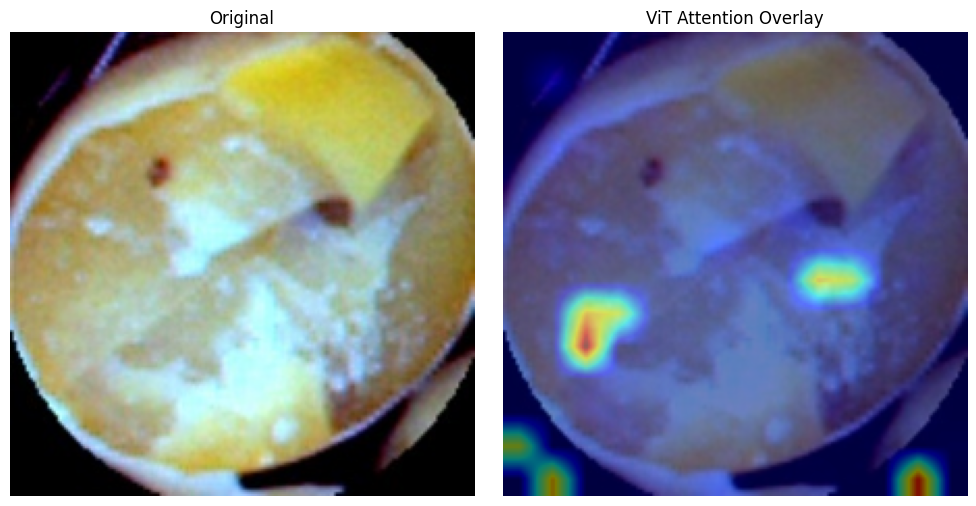

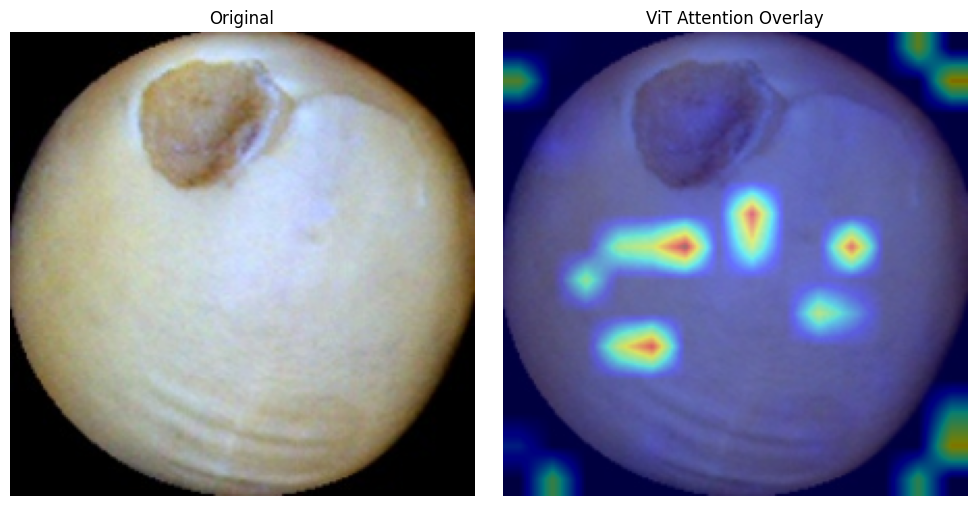

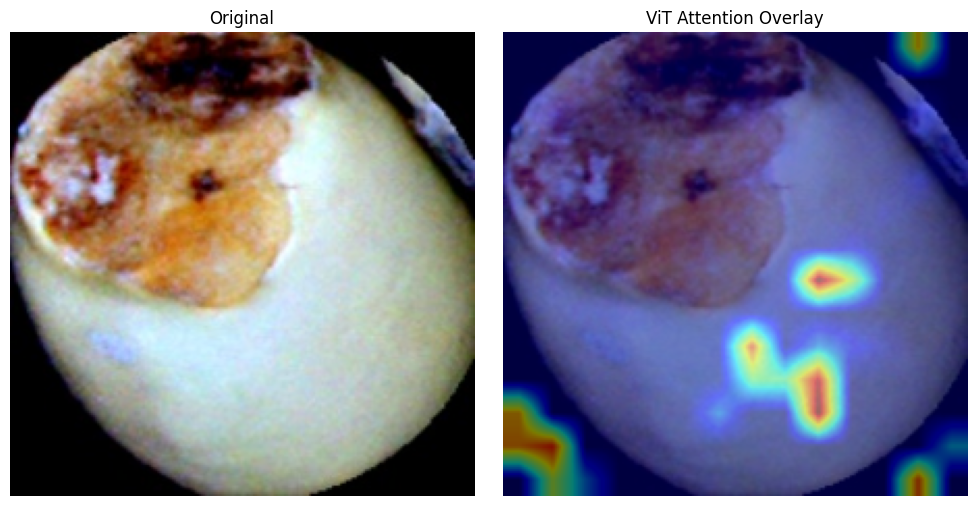

In [ ]:
import matplotlib.pyplot as plt

def get_attention_map(model, image_tensor):
    model.eval()
    x = model._process_input(image_tensor.unsqueeze(0).to(device))
    n = x.shape[0]
    batch_class_token = model.class_token.expand(n, -1, -1)
    x = torch.cat([batch_class_token, x], dim=1)
    x = x + model.encoder.pos_embedding
    for i, layer in enumerate(model.encoder.layers):
        if i == len(model.encoder.layers) - 1:
            y = layer.ln_1(x)
            attn_output, attn_map = layer.self_attention(y, y, y, need_weights=True, average_attn_weights=True)
            return attn_map[0, 0, 1:]
        else:
            x = layer(x)
    return None

def visualize_attention(model, filepath, weight_path):
    model.load_state_dict(torch.load(weight_path))
    img = Image.open(filepath).convert("RGB")
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    img_tensor = transform(img)
    attn = get_attention_map(model, img_tensor)
    grid_size = int(np.sqrt(attn.shape[0]))
    attn_map = attn.reshape(grid_size, grid_size).detach().cpu().numpy()
    attn_map_resized = cv2.resize(attn_map, (224, 224))

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(img.resize((224, 224)))
    axes[0].set_title("Original")
    axes[0].axis('off')
    axes[1].imshow(img.resize((224, 224)))
    axes[1].imshow(attn_map_resized, cmap='jet', alpha=0.5)
    axes[1].set_title("ViT Attention Overlay")
    axes[1].axis('off')
    plt.tight_layout()
    plt.show()

for i in range(3):
    visualize_attention(vit_model, filepaths[test_idx[i]], "best_vit.pth")

In [ ]:
def simulate_lots_and_aggregate(model, weight_path, test_loader, test_idx, labels, class_names,
                                  lot_size=20, defect_classes=None, reject_threshold=0.15, seed=SEED):
    if defect_classes is None:
        defect_classes = [c for c in class_names if c.lower() != 'intact soybeans']
    defect_idx = set(class_names.index(c) for c in defect_classes)

    model.load_state_dict(torch.load(weight_path))
    model.eval()
    all_preds, all_true = [], []
    with torch.no_grad():
        for images, lbls in test_loader:
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_true.extend(lbls.numpy())
    all_preds, all_true = np.array(all_preds), np.array(all_true)

    rng = np.random.RandomState(seed)
    order = rng.permutation(len(all_preds))
    n_lots = len(all_preds) // lot_size

    lot_results = []
    for lot_num in range(n_lots):
        idx = order[lot_num*lot_size : (lot_num+1)*lot_size]
        pred_rate = np.mean([p in defect_idx for p in all_preds[idx]])
        true_rate = np.mean([t in defect_idx for t in all_true[idx]])
        pred_decision = "Rejected" if pred_rate > reject_threshold else "Accepted"
        true_decision = "Rejected" if true_rate > reject_threshold else "Accepted"
        lot_results.append({
            "Lot": lot_num + 1, "Predicted Defect Rate": round(pred_rate, 3),
            "True Defect Rate": round(true_rate, 3), "Predicted Decision": pred_decision,
            "True Decision": true_decision, "Correct": pred_decision == true_decision
        })

    lot_df = pd.DataFrame(lot_results)
    lot_level_acc = lot_df["Correct"].mean()
    print(f"Simulated lots: {n_lots} | Lot-level decision accuracy: {lot_level_acc*100:.2f}%")
    return lot_df, lot_level_acc

lot_df, lot_level_acc = simulate_lots_and_aggregate(
    vit_model, "best_vit.pth", test_loader, test_idx, labels, class_names,
    lot_size=20, reject_threshold=0.15
)

Simulated lots: 36 | Lot-level decision accuracy: 100.00%


In [ ]:
results = pd.DataFrame({
    "Model": ["ViT-B/16", "ResNet-50", "DenseNet-121", "SVM (RBF)", "Random Forest", "LDA"],
    "Accuracy (%)": [vit_acc*100, resnet_acc*100, densenet_acc*100, svm_acc*100, rf_acc*100, lda_acc*100],
})
print(results.to_string(index=False))
print(f"Lot-level accuracy (simulated): {lot_level_acc*100:.2f}%")
print(robustness_df.to_string(index=False))

        Model  Accuracy (%)
     ViT-B/16     95.522388
    ResNet-50     94.843962
 DenseNet-121     92.944369
    SVM (RBF)     78.018996
Random Forest     71.777476
          LDA     71.777476
Lot-level accuracy (simulated): 100.00%
   Perturbation  ViT Accuracy (%)
          Clean             95.52
Brightness +40%             94.17
Brightness -40%             94.17
  Contrast +40%             95.39
  Contrast -40%             95.52
    Rotation 30             95.12
    Rotation 90             95.79


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import shutil
os.makedirs('/content/drive/MyDrive/soybean_final', exist_ok=True)
for f in ["best_vit.pth", "best_resnet50.pth", "best_densenet121.pth"]:
    if os.path.exists(f):
        shutil.copy(f, f"/content/drive/MyDrive/soybean_final/{f}")
results.to_csv("/content/drive/MyDrive/soybean_final/results_table.csv", index=False)
robustness_df.to_csv("/content/drive/MyDrive/soybean_final/robustness_table.csv", index=False)
lot_df.to_csv("/content/drive/MyDrive/soybean_final/lot_level_results.csv", index=False)
print("Saved to Drive")

Mounted at /content/drive
Saved to Drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import shutil
os.makedirs('/content/drive/MyDrive/soybean_final', exist_ok=True)

for f in ["best_vit.pth", "best_resnet50.pth", "best_densenet121.pth"]:
    if os.path.exists(f):
        shutil.copy(f, f"/content/drive/MyDrive/soybean_final/{f}")
        print(f"Saved {f}")
    else:
        print(f"Not found: {f}")

results.to_csv("/content/drive/MyDrive/soybean_final/results_table.csv", index=False)
robustness_df.to_csv("/content/drive/MyDrive/soybean_final/robustness_table.csv", index=False)
lot_df.to_csv("/content/drive/MyDrive/soybean_final/lot_level_results.csv", index=False)
print("Saved to Drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved best_vit.pth
Saved best_resnet50.pth
Saved best_densenet121.pth
Saved to Drive


In [ ]:
defect_classes = [c for c in class_names if c.lower() != 'intact soybeans']
defect_idx = set(class_names.index(c) for c in defect_classes)
overall_defect_rate = np.mean([1 if l in defect_idx else 0 for l in labels])
print(f"Overall defect rate in dataset: {overall_defect_rate*100:.2f}%")

Overall defect rate in dataset: 78.22%


In [ ]:
for thresh in [0.5, 0.6, 0.7, 0.75, 0.8, 0.85]:
    lot_df_t, lot_acc_t = simulate_lots_and_aggregate(
        vit_model, "best_vit.pth", test_loader, test_idx, labels, class_names,
        lot_size=20, reject_threshold=thresh
    )
    accepted_count = (lot_df_t["True Decision"] == "Accepted").sum()
    rejected_count = (lot_df_t["True Decision"] == "Rejected").sum()
    print(f"Threshold {thresh}: Lot Acc={lot_acc_t*100:.2f}% | True Accepted={accepted_count}, True Rejected={rejected_count}\n")

Simulated lots: 36 | Lot-level decision accuracy: 100.00%
Threshold 0.5: Lot Acc=100.00% | True Accepted=0, True Rejected=36

Simulated lots: 36 | Lot-level decision accuracy: 97.22%
Threshold 0.6: Lot Acc=97.22% | True Accepted=1, True Rejected=35

Simulated lots: 36 | Lot-level decision accuracy: 100.00%
Threshold 0.7: Lot Acc=100.00% | True Accepted=2, True Rejected=34

Simulated lots: 36 | Lot-level decision accuracy: 97.22%
Threshold 0.75: Lot Acc=97.22% | True Accepted=3, True Rejected=33

Simulated lots: 36 | Lot-level decision accuracy: 86.11%
Threshold 0.8: Lot Acc=86.11% | True Accepted=12, True Rejected=24

Simulated lots: 36 | Lot-level decision accuracy: 97.22%
Threshold 0.85: Lot Acc=97.22% | True Accepted=23, True Rejected=13



In [ ]:
print("RF accuracy:", rf_acc)
print("LDA accuracy:", lda_acc)
print("Are predictions identical?", np.array_equal(rf_preds, lda_preds))

RF accuracy: 0.7177747625508819
LDA accuracy: 0.7177747625508819
Are predictions identical? False


In [ ]:
for size in [10, 15, 20, 25, 30]:
    lot_df_s, lot_acc_s = simulate_lots_and_aggregate(
        vit_model, "best_vit.pth", test_loader, test_idx, labels, class_names,
        lot_size=size, reject_threshold=0.8
    )
    print(f"Lot size {size}: Accuracy={lot_acc_s*100:.2f}%\n")

Simulated lots: 73 | Lot-level decision accuracy: 94.52%
Lot size 10: Accuracy=94.52%

Simulated lots: 49 | Lot-level decision accuracy: 91.84%
Lot size 15: Accuracy=91.84%

Simulated lots: 36 | Lot-level decision accuracy: 86.11%
Lot size 20: Accuracy=86.11%

Simulated lots: 29 | Lot-level decision accuracy: 89.66%
Lot size 25: Accuracy=89.66%

Simulated lots: 24 | Lot-level decision accuracy: 87.50%
Lot size 30: Accuracy=87.50%



In [ ]:
lot_size_sensitivity = []
for size in [10, 15, 20, 25, 30]:
    lot_df_s, lot_acc_s = simulate_lots_and_aggregate(
        vit_model, "best_vit.pth", test_loader, test_idx, labels, class_names,
        lot_size=size, reject_threshold=0.8
    )
    lot_size_sensitivity.append({"Lot Size": size, "Lot-level Accuracy (%)": round(lot_acc_s*100, 2)})
    print(f"Lot size {size}: Accuracy={lot_acc_s*100:.2f}%\n")

import pandas as pd
lot_size_df = pd.DataFrame(lot_size_sensitivity)
print(lot_size_df)

# Only this part needs Drive (already mounted from before, so this just confirms it)
lot_size_df.to_csv("/content/drive/MyDrive/soybean_final/lot_size_sensitivity.csv", index=False)
print("Saved sensitivity table to Drive")

Simulated lots: 73 | Lot-level decision accuracy: 94.52%
Lot size 10: Accuracy=94.52%

Simulated lots: 49 | Lot-level decision accuracy: 91.84%
Lot size 15: Accuracy=91.84%

Simulated lots: 36 | Lot-level decision accuracy: 86.11%
Lot size 20: Accuracy=86.11%

Simulated lots: 29 | Lot-level decision accuracy: 89.66%
Lot size 25: Accuracy=89.66%

Simulated lots: 24 | Lot-level decision accuracy: 87.50%
Lot size 30: Accuracy=87.50%

   Lot Size  Lot-level Accuracy (%)
0        10                   94.52
1        15                   91.84
2        20                   86.11
3        25                   89.66
4        30                   87.50
Saved sensitivity table to Drive


In [ ]:
import numpy as np
accs = [94.52, 91.84, 86.11, 89.66, 87.50]
print(f"Mean: {np.mean(accs):.2f}%, Std: {np.std(accs):.2f}%")

Mean: 89.93%, Std: 3.01%
